# Indonesia Air Quality: Combined Data & EDA

This notebook combines the **hourly air-quality data** with the **daily summary data**, then adds city coordinates. It provides a complete but straightforward exploratory analysis.

### Questions covered
- What data is available and is it clean?
- How are the two air-quality files combined?
- Which cities and islands have the highest PM2.5?
- How does air quality change over time and during the day?
- Which pollutants are most closely related?

> WHO's 2021 guideline for annual-average PM2.5 is 5 µg/m³. The supplied `exceeds_who_pm25` field is retained as provided; this notebook does not recalculate or reinterpret it.

## 1. Setup

In [1]:
from pathlib import Path
import sys

# Support the project-local PyArrow dependency used when this notebook was built.
for candidate in [Path.cwd(), Path.cwd().parent]:
    local_deps = candidate / '.notebook_deps'
    if local_deps.exists():
        sys.path.insert(0, str(local_deps))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

PROJECT_ROOT = next(
    path for path in [Path.cwd(), Path.cwd().parent]
    if (path / 'dataset').exists()
)
DATA_DIR = PROJECT_ROOT / 'dataset'
print(f'Project root: {PROJECT_ROOT}')

Project root: /home/makarim/Desktop/Collage/Machine Learning/final-project-machine_learning


## 2. Load the three source files

The hourly and daily files are the two main datasets. `cities.csv` is a lookup table used to add coordinates.

In [2]:
hourly = pd.read_parquet(DATA_DIR / 'idn_air_quality_hourly.parquet')
daily = pd.read_csv(DATA_DIR / 'idn_air_quality_daily.csv', parse_dates=['date'])
cities = pd.read_csv(DATA_DIR / 'cities.csv')

overview = pd.DataFrame({
    'dataset': ['Hourly', 'Daily', 'Cities'],
    'rows': [len(hourly), len(daily), len(cities)],
    'columns': [hourly.shape[1], daily.shape[1], cities.shape[1]],
    'duplicate_rows': [hourly.duplicated().sum(), daily.duplicated().sum(), cities.duplicated().sum()],
    'missing_cells': [hourly.isna().sum().sum(), daily.isna().sum().sum(), cities.isna().sum().sum()]
})
display(overview.style.format({'rows': '{:,}', 'missing_cells': '{:,}'}))

,dataset,rows,columns,duplicate_rows,missing_cells
0,Hourly,"1,164,125",14,0,744
1,Daily,"48,515",11,0,62
2,Cities,31,5,0,0


In [3]:
print('Hourly sample')
display(hourly.head(3))
print('Daily sample')
display(daily.head(3))
print('City lookup sample')
display(cities.head(3))

Hourly sample


,city,province,island,time_local,time_utc,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,dust,uv_index,us_aqi
0,Ambon,Maluku,Maluku,2022-08-04 09:00:00,2022-08-04 00:00:00,8.90,15.70,85.00,0.30,0.20,37.00,0.00,2.65,NaN
1,Ambon,Maluku,Maluku,2022-08-04 10:00:00,2022-08-04 01:00:00,8.70,15.30,84.00,0.20,0.20,37.00,0.00,4.90,NaN
2,Ambon,Maluku,Maluku,2022-08-04 11:00:00,2022-08-04 02:00:00,8.90,15.60,83.00,0.20,0.30,37.00,0.00,6.95,NaN


Daily sample


,city,province,island,date,pm2_5_mean,pm2_5_max,pm10_mean,us_aqi_mean,us_aqi_max,hours,exceeds_who_pm25
0,Ambon,Maluku,Maluku,2022-08-04,7.12,9.80,12.47,NaN,NaN,15,False
1,Ambon,Maluku,Maluku,2022-08-05,6.34,8.40,10.90,32.33,35.00,24,False
2,Ambon,Maluku,Maluku,2022-08-06,5.52,8.60,9.59,36.08,38.00,24,False


City lookup sample


,city,province,island,latitude,longitude
0,Ambon,Maluku,Maluku,-3.70,128.18
1,Balikpapan,Kalimantan Timur,Kalimantan,-1.24,116.85
2,Banda Aceh,Aceh,Sumatra,5.55,95.32


## 3. Data quality checks

In [4]:
def missing_summary(frame, name):
    missing = frame.isna().sum()
    result = pd.DataFrame({
        'dataset': name,
        'column': missing.index,
        'missing_count': missing.values,
        'missing_pct': (missing.values / len(frame) * 100)
    })
    return result[result['missing_count'] > 0]

missing = pd.concat([
    missing_summary(hourly, 'Hourly'),
    missing_summary(daily, 'Daily'),
    missing_summary(cities, 'Cities')
], ignore_index=True)
display(missing.style.format({'missing_count': '{:,}', 'missing_pct': '{:.3f}%'}))

daily_key = ['city', 'province', 'island', 'date']
city_key = ['city', 'province', 'island']
print('Duplicate daily keys:', daily.duplicated(daily_key).sum())
print('Duplicate city lookup keys:', cities.duplicated(city_key).sum())
print('Hourly period:', hourly['time_local'].min(), 'to', hourly['time_local'].max())
print('Daily period: ', daily['date'].min().date(), 'to', daily['date'].max().date())
print('Cities in hourly / daily / lookup:', hourly['city'].nunique(), daily['city'].nunique(), cities['city'].nunique())

,dataset,column,missing_count,missing_pct
0,Hourly,us_aqi,744,0.064%
1,Daily,us_aqi_mean,31,0.064%
2,Daily,us_aqi_max,31,0.064%


Duplicate daily keys: 0
Duplicate city lookup keys: 0
Hourly period: 2022-08-04 07:00:00 to 2026-11-15 23:00:00
Daily period:  2022-08-04 to 2026-11-15
Cities in hourly / daily / lookup: 31 31 31


### Quality notes

Missing AQI values are kept as missing; they are not filled because guessing them could bias the analysis. Exact duplicate rows and duplicate merge keys are checked before combining the files.

## 4. Unite the hourly and daily data

The hourly observations are aggregated to one row per city and local date. Extra hourly pollutant averages are joined to the supplied daily summary, then coordinates are added.

In [5]:
hourly = hourly.copy()
hourly['date'] = hourly['time_local'].dt.normalize()
hourly['hour'] = hourly['time_local'].dt.hour

extra_pollutants = [
    'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide',
    'ozone', 'dust', 'uv_index'
]
hourly_daily = (
    hourly.groupby(daily_key, as_index=False)
          .agg(**{f'{column}_mean': (column, 'mean') for column in extra_pollutants},
               hourly_rows=('time_local', 'size'))
)

combined = daily.merge(
    hourly_daily, on=daily_key, how='outer', validate='one_to_one', indicator=True
)
merge_counts = combined['_merge'].value_counts().rename_axis('merge_status').to_frame('rows')
display(merge_counts)

combined = (
    combined.drop(columns='_merge')
            .merge(cities, on=city_key, how='left', validate='many_to_one')
            .sort_values(['city', 'date'])
            .reset_index(drop=True)
)

assert not combined.duplicated(daily_key).any(), 'Combined data contains duplicate city-date rows.'
assert combined[['latitude', 'longitude']].notna().all().all(), 'Some cities did not receive coordinates.'
print(f'Combined dataset: {combined.shape[0]:,} rows × {combined.shape[1]} columns')
display(combined.head())

,rows
merge_status,
both,48515
left_only,0
right_only,0


Combined dataset: 48,515 rows × 20 columns


,city,province,island,date,pm2_5_mean,pm2_5_max,pm10_mean,us_aqi_mean,us_aqi_max,hours,exceeds_who_pm25,carbon_monoxide_mean,nitrogen_dioxide_mean,sulphur_dioxide_mean,ozone_mean,dust_mean,uv_index_mean,hourly_rows,latitude,longitude
0,Ambon,Maluku,Maluku,2022-08-04,7.12,9.80,12.47,NaN,NaN,15,False,80.20,0.32,0.29,34.80,0.00,2.47,15,-3.70,128.18
1,Ambon,Maluku,Maluku,2022-08-05,6.34,8.40,10.90,32.33,35.00,24,False,77.54,0.28,0.29,34.96,0.00,1.98,24,-3.70,128.18
2,Ambon,Maluku,Maluku,2022-08-06,5.52,8.60,9.59,36.08,38.00,24,False,83.17,0.38,0.22,33.58,0.00,0.28,24,-3.70,128.18
3,Ambon,Maluku,Maluku,2022-08-07,3.42,5.30,5.74,23.58,31.00,24,False,86.21,0.25,0.25,31.88,0.00,1.98,24,-3.70,128.18
4,Ambon,Maluku,Maluku,2022-08-08,4.36,5.60,7.43,21.08,24.00,24,False,83.79,0.27,0.23,32.42,0.00,2.10,24,-3.70,128.18


In [6]:
output_path = DATA_DIR / 'idn_air_quality_unified_daily.csv'
combined.to_csv(output_path, index=False)
print(f'Saved united daily dataset to: {output_path}')

Saved united daily dataset to: /home/makarim/Desktop/Collage/Machine Learning/final-project-machine_learning/dataset/idn_air_quality_unified_daily.csv


## 5. Summary statistics

In [7]:
summary_columns = [
    'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'us_aqi_mean',
    'carbon_monoxide_mean', 'nitrogen_dioxide_mean',
    'sulphur_dioxide_mean', 'ozone_mean', 'dust_mean', 'uv_index_mean'
]
display(combined[summary_columns].describe().T.round(2))

coverage = combined['hours'].value_counts().sort_index().rename_axis('hours_in_day').to_frame('days')
coverage['percent'] = coverage['days'] / len(combined) * 100
display(coverage.tail(8).style.format({'days': '{:,}', 'percent': '{:.2f}%'}))

,count,mean,std,min,25%,50%,75%,max
pm2_5_mean,"48,515.00",21.28,30.05,0.48,8.85,13.57,24.34,"1,228.37"
pm2_5_max,"48,515.00",37.09,73.94,0.60,13.00,21.70,41.70,"3,255.90"
pm10_mean,"48,515.00",26.63,32.28,0.69,12.14,18.08,30.87,"1,243.94"
us_aqi_mean,"48,484.00",70.76,42.33,12.92,48.46,58.75,80.33,"1,115.75"
carbon_monoxide_mean,"48,515.00",556.35,703.26,59.00,211.42,350.79,650.38,"22,089.96"
nitrogen_dioxide_mean,"48,515.00",11.93,16.05,0.00,2.82,6.25,13.75,397.41
sulphur_dioxide_mean,"48,515.00",7.75,12.66,0.01,1.35,2.98,7.26,355.20
ozone_mean,"48,515.00",55.55,24.52,9.62,39.25,50.29,65.48,300.54
dust_mean,"48,515.00",0.15,0.78,0.00,0.00,0.00,0.00,28.33
uv_index_mean,"48,515.00",1.96,0.55,0.11,1.59,1.98,2.35,3.71


,days,percent
hours_in_day,,
15,4,0.01%
16,10,0.02%
17,17,0.04%
24,"48,484",99.94%


## 6. Distributions

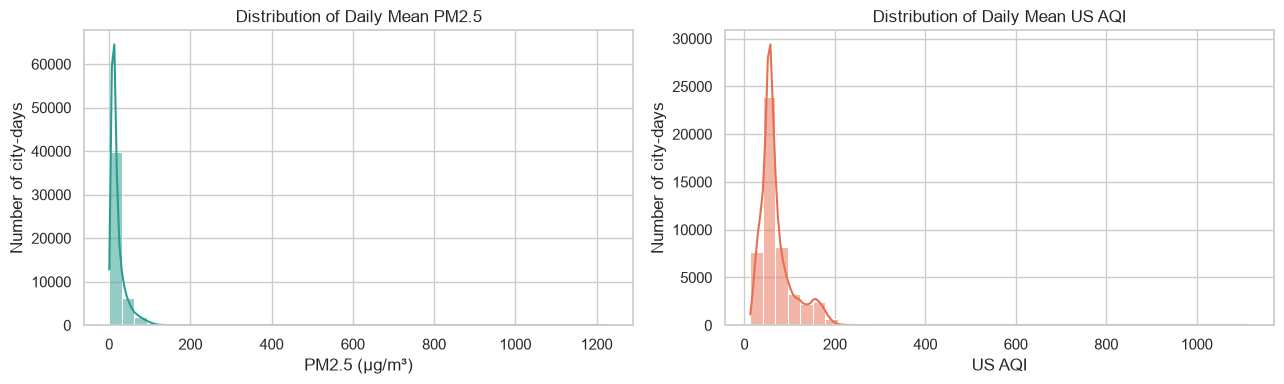

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(combined['pm2_5_mean'], bins=40, kde=True, ax=axes[0], color='#2a9d8f')
axes[0].set(title='Distribution of Daily Mean PM2.5', xlabel='PM2.5 (µg/m³)', ylabel='Number of city-days')
sns.histplot(combined['us_aqi_mean'].dropna(), bins=40, kde=True, ax=axes[1], color='#e76f51')
axes[1].set(title='Distribution of Daily Mean US AQI', xlabel='US AQI', ylabel='Number of city-days')
plt.tight_layout()
plt.show()

## 7. Comparison by city and island

,city,province,mean_pm25,median_pm25,mean_aqi,who_exceedance_pct,observed_days
8,Jakarta,DKI Jakarta,67.59,68.56,153.5,99.0%,"1,565"
4,Bandung,Jawa Barat,55.81,51.98,138.3,99.6%,"1,565"
19,Palangka Raya,Kalimantan Tengah,38.66,9.48,77.3,18.1%,"1,565"
26,Serang,Banten,38.24,37.23,110.5,82.3%,"1,565"
28,Surabaya,Jawa Timur,38.18,34.38,107.9,96.5%,"1,565"
30,Yogyakarta,DI Yogyakarta,35.55,30.27,100.0,84.5%,"1,565"
17,Medan,Sumatera Utara,30.98,29.98,94.1,98.8%,"1,565"
25,Semarang,Jawa Tengah,29.51,28.96,107.2,91.2%,"1,565"
3,Bandar Lampung,Lampung,29.38,26.48,89.8,90.4%,"1,565"
14,Malang,Jawa Timur,21.64,19.95,74.1,68.9%,"1,565"


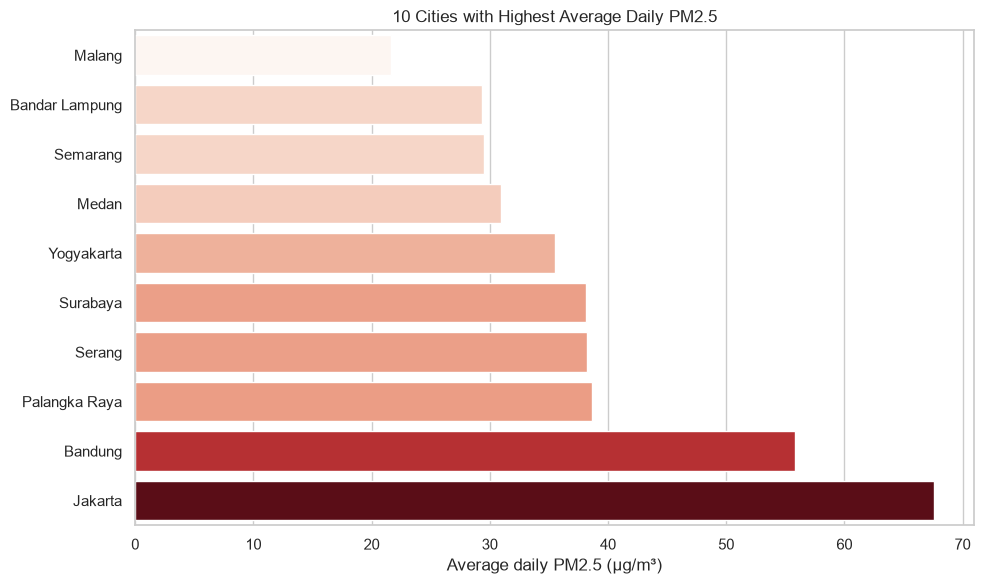

In [9]:
city_summary = (
    combined.groupby(['city', 'province'], as_index=False)
            .agg(mean_pm25=('pm2_5_mean', 'mean'),
                 median_pm25=('pm2_5_mean', 'median'),
                 mean_aqi=('us_aqi_mean', 'mean'),
                 who_exceedance_pct=('exceeds_who_pm25', lambda values: values.mean() * 100),
                 observed_days=('date', 'nunique'))
            .sort_values('mean_pm25', ascending=False)
)
display(city_summary.head(10).style.format({
    'mean_pm25': '{:.2f}', 'median_pm25': '{:.2f}', 'mean_aqi': '{:.1f}',
    'who_exceedance_pct': '{:.1f}%', 'observed_days': '{:,}'
}))

plt.figure(figsize=(10, 6))
plot_data = city_summary.head(10).sort_values('mean_pm25')
sns.barplot(data=plot_data, x='mean_pm25', y='city', hue='mean_pm25', palette='Reds', legend=False)
plt.title('10 Cities with Highest Average Daily PM2.5')
plt.xlabel('Average daily PM2.5 (µg/m³)')
plt.ylabel('')
plt.tight_layout()
plt.show()

,island,mean_pm25,mean_aqi,who_exceedance_pct,observed_days
1,Java,40.93,113.1,88.9%,"10,955"
6,Sumatra,20.44,71.1,58.6%,"12,520"
2,Kalimantan,19.73,63.5,25.3%,"7,825"
5,Sulawesi,12.79,54.7,27.1%,"6,260"
0,Bali & Nusa Tenggara,10.51,50.4,11.3%,"4,695"
3,Maluku,7.07,36.4,4.2%,"3,130"
4,Papua,7.03,36.4,2.8%,"3,130"


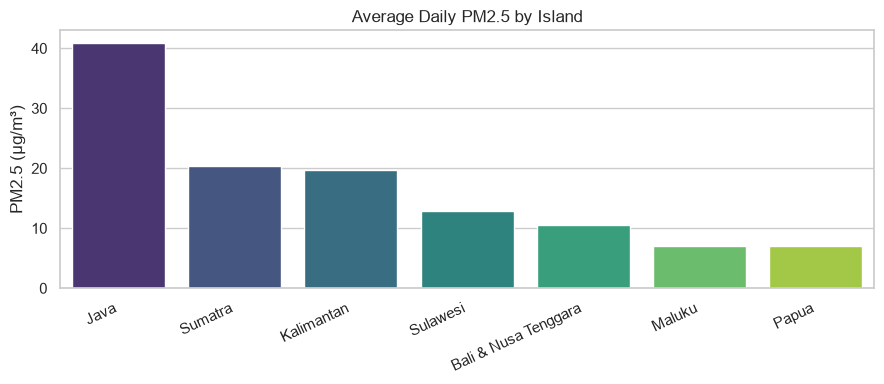

In [10]:
island_summary = (
    combined.groupby('island', as_index=False)
            .agg(mean_pm25=('pm2_5_mean', 'mean'),
                 mean_aqi=('us_aqi_mean', 'mean'),
                 who_exceedance_pct=('exceeds_who_pm25', lambda values: values.mean() * 100),
                 observed_days=('date', 'size'))
            .sort_values('mean_pm25', ascending=False)
)
display(island_summary.style.format({
    'mean_pm25': '{:.2f}', 'mean_aqi': '{:.1f}',
    'who_exceedance_pct': '{:.1f}%', 'observed_days': '{:,}'
}))

plt.figure(figsize=(9, 4))
sns.barplot(data=island_summary, x='island', y='mean_pm25', hue='island', palette='viridis', legend=False)
plt.title('Average Daily PM2.5 by Island')
plt.xlabel('')
plt.ylabel('PM2.5 (µg/m³)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 8. Change over time

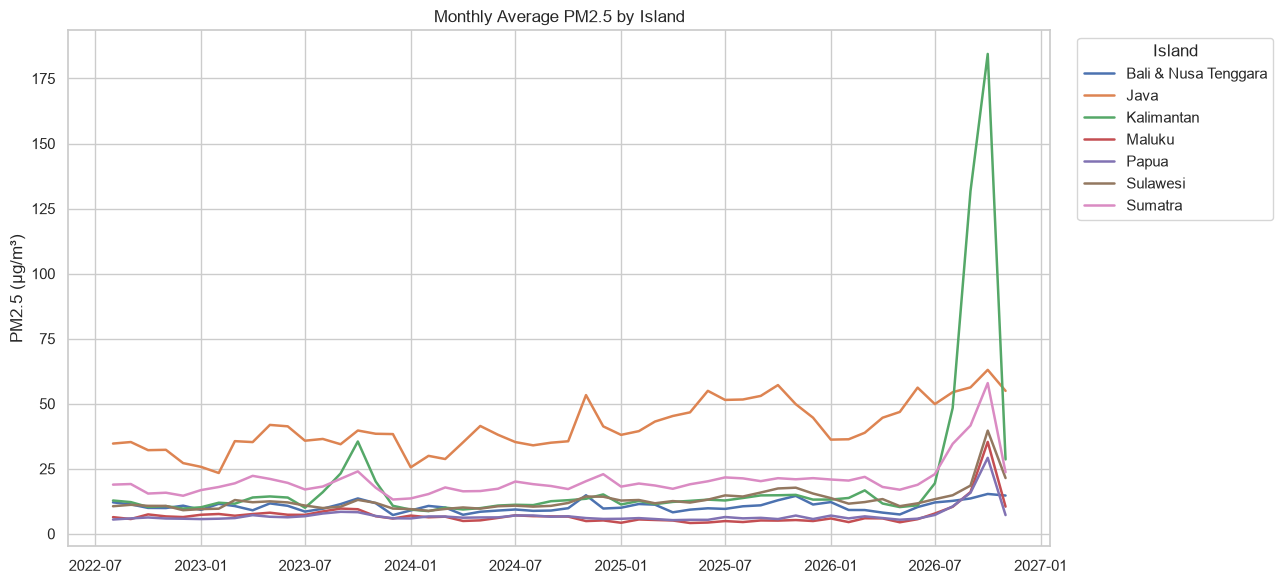

In [11]:
monthly = (
    combined.set_index('date')
            .groupby('island')['pm2_5_mean']
            .resample('MS').mean()
            .rename('mean_pm25')
            .reset_index()
)
plt.figure(figsize=(13, 6))
sns.lineplot(data=monthly, x='date', y='mean_pm25', hue='island', linewidth=1.8)
plt.title('Monthly Average PM2.5 by Island')
plt.xlabel('')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend(title='Island', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 9. Typical hourly pattern

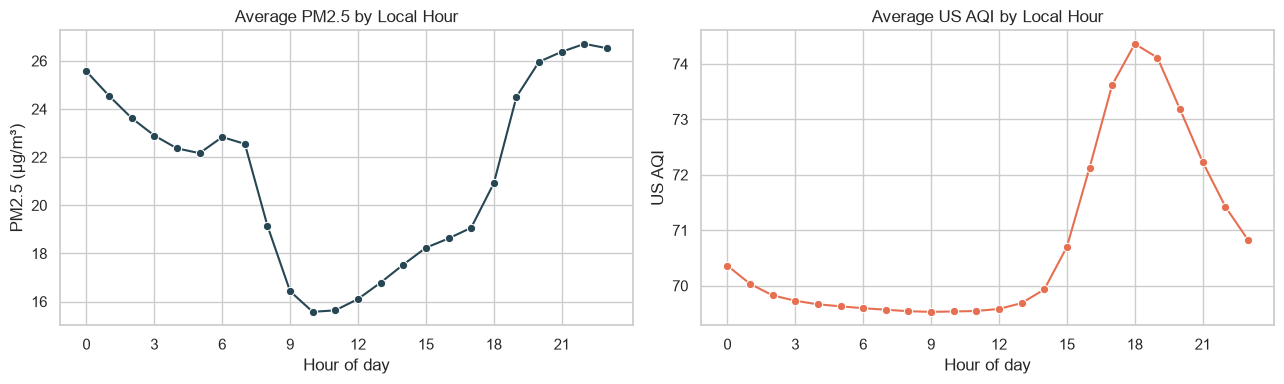

In [12]:
hour_pattern = (
    hourly.groupby('hour', as_index=False)
          .agg(pm2_5=('pm2_5', 'mean'), pm10=('pm10', 'mean'), us_aqi=('us_aqi', 'mean'))
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(data=hour_pattern, x='hour', y='pm2_5', marker='o', ax=axes[0], color='#264653')
axes[0].set(title='Average PM2.5 by Local Hour', xlabel='Hour of day', ylabel='PM2.5 (µg/m³)', xticks=range(0, 24, 3))
sns.lineplot(data=hour_pattern, x='hour', y='us_aqi', marker='o', ax=axes[1], color='#e76f51')
axes[1].set(title='Average US AQI by Local Hour', xlabel='Hour of day', ylabel='US AQI', xticks=range(0, 24, 3))
plt.tight_layout()
plt.show()

## 10. Relationships between pollutants

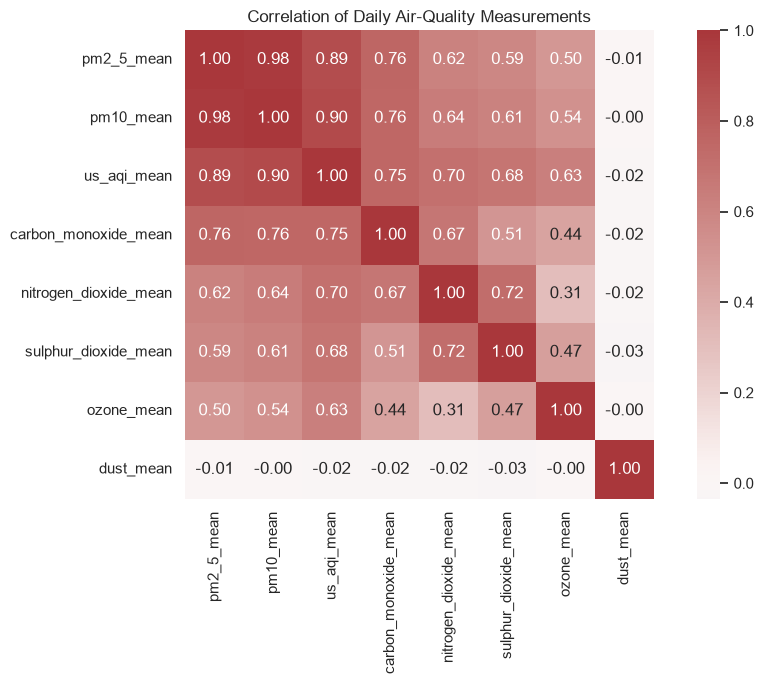

In [13]:
correlation_columns = [
    'pm2_5_mean', 'pm10_mean', 'us_aqi_mean', 'carbon_monoxide_mean',
    'nitrogen_dioxide_mean', 'sulphur_dioxide_mean', 'ozone_mean', 'dust_mean'
]
correlations = combined[correlation_columns].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='vlag', center=0, square=True)
plt.title('Correlation of Daily Air-Quality Measurements')
plt.tight_layout()
plt.show()

## 11. Key findings (generated from the data)

In [14]:
highest_city = city_summary.iloc[0]
highest_island = island_summary.iloc[0]
peak_hour = hour_pattern.loc[hour_pattern['pm2_5'].idxmax()]
pm25_links = correlations['pm2_5_mean'].drop('pm2_5_mean').abs().sort_values(ascending=False)
strongest_variable = pm25_links.index[0].replace('_mean', '').replace('_', ' ').title()
overall_exceedance = combined['exceeds_who_pm25'].mean() * 100

print(f"• Highest average city: {highest_city['city']} ({highest_city['mean_pm25']:.2f} µg/m³).")
print(f"• Highest average island group: {highest_island['island']} ({highest_island['mean_pm25']:.2f} µg/m³).")
print(f"• {overall_exceedance:.1f}% of city-days are marked as exceeding the supplied WHO PM2.5 threshold.")
print(f"• The typical hourly PM2.5 peak occurs around {int(peak_hour['hour']):02d}:00 local time.")
print(f"• The strongest absolute daily correlation with PM2.5 is {strongest_variable} (r={pm25_links.iloc[0]:.2f}).")
print('• These are descriptive associations, not evidence of causation.')

• Highest average city: Jakarta (67.59 µg/m³).
• Highest average island group: Java (40.93 µg/m³).
• 44.3% of city-days are marked as exceeding the supplied WHO PM2.5 threshold.
• The typical hourly PM2.5 peak occurs around 22:00 local time.
• The strongest absolute daily correlation with PM2.5 is Pm10 (r=0.98).
• These are descriptive associations, not evidence of causation.


## Conclusion

The notebook has checked, combined, and explored the data at both daily and hourly levels. The exported `idn_air_quality_unified_daily.csv` is ready for later modeling or deeper analysis. Before modeling, consider time-based train/test splits and avoid interpreting correlation as causation.